# NB5c — rule R1: PVSetFormer or LightGBM as the index forecaster (validation units only)

D25, D36, D37. Final PVSetFormer round: **V12_5s** (`results/nb5c_variants/V12_5s/`, 5 seeds); LightGBM: `results/nb5c_variants/LGB_seeds/` (5 seeds). Both were scored by `tools/r1_score.py` on exactly the slots NB5a scored. No test event is used.

**Rule, fixed before the final rounds (D25, D37):** PVSetFormer becomes the main index forecaster only if the median over the 10 validation units of the nRMSE at 1 h of its 5-seed ensemble is lower than that of LightGBM's 5-seed ensemble (seeds C.SEED + 1 … C.SEED + 5 for both). Otherwise LightGBM stays the main index forecaster. Since D73 the title no longer depends on R1. The per-seed mean and s.d., the units won and a paired Wilcoxon signed-rank test over the 10 units are reported beside the rule; they do not change it.

**Count of design variants (D73):** the PVSetFormer rounds of `log.csv` (names starting with V; a 5-seed re-run counts as the same variant), not the TimeXer runs (TX), the R2 runs (A6e) or the A4c row; the hyperparameter searches are counted separately.

**Caveat (D36):** the design rounds and this comparison use the same 10 validation units, which favours the model with more rounds (PVSetFormer). The test run is the unbiased check.

In [1]:
import os, sys, json, time, hashlib
from pathlib import Path
import numpy as np, pandas as pd, yaml
from scipy.stats import wilcoxon
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT / 'src'))
from pvcold import config as C, audit as A, forecast as FC, setformer as SF
pd.set_option('display.width', 200)
FINAL = 'V12_5s'
t0 = time.time(); H1 = C.PRIMARY_HORIZON
VD = C.RESULTS / 'nb5c_variants'
sp = json.loads((VD / FINAL / 'summary.json').read_text()); sl = json.loads((VD / 'LGB_seeds' / 'summary.json').read_text())
nb5 = json.loads((C.RESULTS / 'nb5a_dev' / 'summary.json').read_text())
scp = pd.read_csv(VD / FINAL / 'scores.csv'); scl = pd.read_csv(VD / 'LGB_seeds' / 'scores.csv')
seeds_p = sorted(int(s) for s in scp.seed.unique() if s > 0); seeds_l = list(sl['seeds'])
assert sp['seeds'] == 5 and seeds_p == seeds_l == [C.SEED + i for i in range(1, 6)], (seeds_p, seeds_l)
assert sl['lgb_config_sha256'] == nb5['lgb_config_sha256'] and sl['check_passed']
k = ['event', 'seed', 'h']
both = scp.merge(scl, on=k, suffixes=('_pvsf', '_lgb'))
assert len(both) == len(scp) == len(scl) and (both['n_pvsf'] == both['n_lgb']).all(), 'different slots'
log = pd.read_csv(VD / 'log.csv')
print('PVSetFormer', FINAL, sp['cfg'], '| parameters', sp['n_params'])
print('LightGBM', sl['params'], '| seeds', seeds_l, '| slots per unit and horizon identical')
VARIANTS = list(dict.fromkeys(v.removesuffix('_5s') for v in log.variant if v.startswith('V')))   # design rounds, in order (V3 was logged twice, D36)
SEARCHES = sorted(p.name for p in VD.glob('CV*') if json.loads((p / 'summary.json').read_text())['base'].get('arch', 'pvsf') == 'pvsf')
assert FINAL.removesuffix('_5s') in VARIANTS
print('PVSetFormer design variants logged before this decision:', len(VARIANTS), VARIANTS)
print('PVSetFormer hyperparameter searches:', SEARCHES)

PVSetFormer V12_5s {'d': 64, 'heads': 4, 'n_sky': 4, 'n_enc': 2, 'n_dec': 2, 'dropout': 0.1, 'lr': 0.001, 'weight_decay': 0.5, 'batch': 256, 'max_epochs': 100, 'patience': 15, 'donor_dropout': 0.1, 'fleet_token': 1, 'balance': 1, 'lin': 1, 'aux': 0.0, 'summary_only': 0, 'vol': 0, 'vgate': 0, 'hmask': 0, 'hhead': 0, 'hhead_n': 0, 'donor_id': 0, 'donor_rel': 0, 'ext': '', 'vlin': 0, 'vmed': 1, 'vmed_n': 2, 'arch': 'pvsf'} | parameters 224331
LightGBM {'num_leaves': 31, 'learning_rate': 0.05, 'min_data_in_leaf': 200} | seeds [20261119, 20261120, 20261121, 20261122, 20261123] | slots per unit and horizon identical
PVSetFormer design variants logged before this decision: 20 ['V1', 'V2', 'V3', 'V4a', 'V4b', 'V5a', 'V5b', 'V6a', 'V6b', 'V7a', 'V7b', 'V8a', 'V8b', 'V10a', 'V9', 'V11a', 'V12', 'V13', 'V14', 'V15']
PVSetFormer hyperparameter searches: ['CV2', 'CV4']


## Medians over the 10 validation units, per horizon

In [2]:
MET = ['nRMSE', 'CRPS', 'PICP80']
rows = []
for model, sc in [('PVSF', scp), ('LGB', scl)]:
    ens = sc[sc.seed == 0].groupby('h')[MET].median()
    ps = sc[sc.seed > 0].groupby(['seed', 'h'])[MET].median().groupby('h').agg(['mean', 'std', 'min', 'max'])
    for h in FC.H:
        rows.append({'model': model, 'h': h, **{f'{m}_ens': ens.loc[h, m] for m in MET},
                     **{f'{m}_seed_{s}': ps.loc[h, (m, s)] for m in MET for s in ['mean', 'std', 'min', 'max']}})
tab = pd.DataFrame(rows)
print(tab.pivot(index='h', columns='model', values='nRMSE_ens').round(4).to_string())
print(tab.pivot(index='h', columns='model', values='CRPS_ens').round(4).to_string())
print(tab[['model', 'h', 'nRMSE_seed_mean', 'nRMSE_seed_std']].round(4).to_string(index=False))

model     LGB    PVSF
h                    
1      0.1291  0.1329
2      0.1562  0.1567
4      0.1813  0.1778
8      0.2103  0.2072
16     0.2368  0.2315
24     0.2180  0.2056
model     LGB    PVSF
h                    
1      0.0617  0.0650
2      0.0772  0.0798
4      0.0937  0.0945
8      0.1144  0.1110
16     0.1295  0.1254
24     0.1167  0.1077
model  h  nRMSE_seed_mean  nRMSE_seed_std
 PVSF  1           0.1336          0.0020
 PVSF  2           0.1581          0.0025
 PVSF  4           0.1809          0.0035
 PVSF  8           0.2097          0.0043
 PVSF 16           0.2333          0.0043
 PVSF 24           0.2119          0.0077
  LGB  1           0.1291          0.0001
  LGB  2           0.1562          0.0001
  LGB  4           0.1812          0.0002
  LGB  8           0.2104          0.0002
  LGB 16           0.2368          0.0006
  LGB 24           0.2180          0.0005


## Rule R1 at 1 h

In [3]:
e = both[both.seed == 0]
u = e[e.h == H1].set_index('event')[['nRMSE_pvsf', 'nRMSE_lgb']]
u['diff'] = u.nRMSE_pvsf - u.nRMSE_lgb; u['pct'] = 100 * u['diff'] / u.nRMSE_lgb
r_p, r_l = float(u.nRMSE_pvsf.median()), float(u.nRMSE_lgb.median())
PVSF_MAIN = bool(r_p < r_l)
won = int((u['diff'] < 0).sum())
wx = wilcoxon(u.nRMSE_pvsf, u.nRMSE_lgb)
won_h = e.assign(w=e.nRMSE_pvsf < e.nRMSE_lgb).groupby('h')['w'].sum().astype(int)
print(u.round(4).to_string())
print('median nRMSE at 1 h: PVSetFormer ensemble %.5f vs LightGBM ensemble %.5f (%.2f%%) | units won %d of %d | '
      'Wilcoxon p = %.3f' % (r_p, r_l, 100 * (r_p / r_l - 1), won, len(u), wx.pvalue))
print('units won by horizon:', won_h.to_dict())
print('R1: PVSetFormer becomes the main index forecaster:', PVSF_MAIN)

                   nRMSE_pvsf  nRMSE_lgb    diff     pct
event                                                   
SQ567                  0.1343     0.1351 -0.0008 -0.6219
UG Hall2 2F            0.1332     0.1446 -0.0114 -7.8818
UG Hall2 RF            0.1802     0.1830 -0.0028 -1.5205
Zone A1                0.1644     0.1649 -0.0006 -0.3345
Zone A4                0.1753     0.1779 -0.0026 -1.4435
Zone A2 1              0.1754     0.1831 -0.0077 -4.2144
SQ Apartment1-12       0.1923     0.1863  0.0060  3.2234
SQ Apartment13-24      0.1924     0.1876  0.0049  2.5933
SQ Apartment25-36      0.1888     0.1871  0.0016  0.8598
SQ Apartment37-48      0.1833     0.1796  0.0037  2.0456
median nRMSE at 1 h: PVSetFormer ensemble 0.17782 vs LightGBM ensemble 0.18130 (-1.92%) | units won 6 of 10 | Wilcoxon p = 0.770
units won by horizon: {1: 5, 2: 5, 4: 6, 8: 7, 16: 10, 24: 9}
R1: PVSetFormer becomes the main index forecaster: True


## Figure (development record)

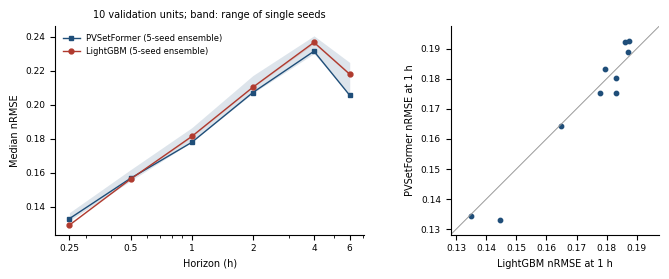

In [4]:
import matplotlib.pyplot as plt
A._style()
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.8))
x = np.array(FC.H) * 0.25
for model, c, mk, lab in [('PVSF', '#1f4e79', 's', 'PVSetFormer'), ('LGB', '#b03a2e', 'o', 'LightGBM')]:
    t = tab[tab.model == model].set_index('h').loc[FC.H]
    ax[0].fill_between(x, t.nRMSE_seed_min, t.nRMSE_seed_max, color=c, alpha=0.15, lw=0)
    ax[0].plot(x, t.nRMSE_ens, marker=mk, ms=3.5, color=c, lw=1, label=lab + ' (5-seed ensemble)')
ax[0].set_xscale('log'); ax[0].set_xticks(x); ax[0].set_xticklabels(['0.25', '0.5', '1', '2', '4', '6'])
ax[0].set_xlabel('Horizon (h)'); ax[0].set_ylabel('Median nRMSE'); ax[0].legend(frameon=False, fontsize=6)
lim = [min(u.min(numeric_only=True)[['nRMSE_pvsf', 'nRMSE_lgb']]) - 0.005, max(u.max(numeric_only=True)[['nRMSE_pvsf', 'nRMSE_lgb']]) + 0.005]
ax[1].plot(lim, lim, color='0.6', lw=0.7)
ax[1].scatter(u.nRMSE_lgb, u.nRMSE_pvsf, s=10, color='#1f4e79')
ax[1].set_xlim(lim); ax[1].set_ylim(lim); ax[1].set_aspect('equal')
ax[1].set_xlabel('LightGBM nRMSE at 1 h'); ax[1].set_ylabel('PVSetFormer nRMSE at 1 h')
ax[0].set_title('10 validation units; band: range of single seeds', fontsize=7); fig.tight_layout()

## Outputs (all-or-nothing); the decision joins the frozen part 2 as part 2c

In [5]:
part2c = {'part': '2c', 'rule': 'R1 (D25, D37): median validation nRMSE at 1 h, 5-seed ensembles of both models',
          'main_index_forecaster': 'PVSetFormer' if PVSF_MAIN else 'LightGBM',
          'seeds': seeds_l, 'ensemble': 'mean of the sorted quantiles across seeds, sorted again',
          'pvsetformer_variant': FINAL, 'pvsetformer_cfg': sp['cfg'], 'pvsetformer_n_params': sp['n_params'],
          'lgb_config_sha256': nb5['lgb_config_sha256'], 'lgb_params': sl['params'],
          'R1_pvsf_ensemble': round(r_p, 6), 'R1_lgb_ensemble': round(r_l, 6),
          'variants_before_decision': len(VARIANTS), 'design_variants': VARIANTS,
          'searches_before_decision': SEARCHES}
P2C_TEXT = yaml.safe_dump(part2c, sort_keys=True)
P2C_HASH = hashlib.sha256(P2C_TEXT.encode()).hexdigest()
summary = {'notebook': 'NB5c_R1_decision', 'environment': A.versions(), 'runtime_s': round(time.time() - t0, 1),
           'final_variant': FINAL, 'pvsf_summary_sha256': hashlib.sha256((VD / FINAL / 'summary.json').read_bytes()).hexdigest(),
           'lgb_seeds_summary_sha256': hashlib.sha256((VD / 'LGB_seeds' / 'summary.json').read_bytes()).hexdigest(),
           'R1_pvsf_ensemble': r_p, 'R1_lgb_ensemble': r_l, 'R1_rel_diff_pct': 100 * (r_p / r_l - 1),
           'R1_pvsf_seed_mean': float(tab.query('model == "PVSF" and h == @H1').nRMSE_seed_mean.iloc[0]),
           'R1_pvsf_seed_sd': float(tab.query('model == "PVSF" and h == @H1').nRMSE_seed_std.iloc[0]),
           'R1_lgb_seed_mean': float(tab.query('model == "LGB" and h == @H1').nRMSE_seed_mean.iloc[0]),
           'R1_lgb_seed_sd': float(tab.query('model == "LGB" and h == @H1').nRMSE_seed_std.iloc[0]),
           'units_won_1h': won, 'wilcoxon_p_1h': float(wx.pvalue), 'units_won_by_h': won_h.to_dict(),
           'pvsf_main': PVSF_MAIN, 'part2c_sha256': P2C_HASH, 'variants_before_decision': len(VARIANTS),
           'design_variants': VARIANTS, 'searches_before_decision': SEARCHES}
out = A.write_outputs('nb5c_r1', {'r1_medians': tab, 'r1_units_1h': u.reset_index(), 'r1_pairs': both}, summary,
                      {'fig_r1': fig}, texts={'r1_config_part2c.yaml': P2C_TEXT})
print('part 2c sha256:', P2C_HASH)
print('written to', out, '|', sorted(x.name for x in out.iterdir()))

part 2c sha256: f947effd8c9c62b6799f4e5dd15d042d92357157b1c69385afc21b1ce96ad88a
written to C:\Users\Dell\Desktop\phd_ehtp\pv paper\results\nb5c_r1 | ['figures', 'r1_config_part2c.yaml', 'r1_medians.csv', 'r1_pairs.csv', 'r1_units_1h.csv', 'summary.json']
